# TP3 Dataset « normal » : prix des voitures en Pologne - OZEL IBRAHIM

Objectif : prédire le prix de vente d'une voiture d'occasion à partir de ses caractéristiques (marque, modèle, année, kilométrage, moteur, carburant, région).

Chaîne suivie : **EDA → prétraitement → transformation → ML → évaluation**.

Données : [Car Prices Poland (Kaggle)](https://www.kaggle.com/datasets/aleksandrglotov/car-prices-poland), un seul fichier CSV d'environ 10 Mo, annonces récupérées en janvier 2022 sur un site de vente polonais. Prix en złotys (PLN).

C'est un problème de **régression** (la cible `price` est un nombre).

## Contribution

**Le notebook s'exécute-t-il de bout en bout ?** Oui : toutes les cellules s'exécutent sans erreur, la partie pandas / scikit-learn (sections 1 à 6) comme la partie PySpark (section 7).

**Problèmes rencontrés**
- Prix très asymétrique (skew de 3,67) : on travaille sur `log(1 + prix)`.
- Colonnes à forte cardinalité (`model` : 328 valeurs, `generation_name` : 364, `city` : 4 427) : un one-hot créerait des milliers de colonnes, donc on utilise un target encoding et on retire `city`.
- 6 473 doublons et des valeurs aberrantes (prix à 500 PLN, 2,8 millions de km).
- Sous Windows, joblib affiche un avertissement (`wmic` introuvable) qui ne change pas les résultats.
- Spark : avec les 200 partitions de shuffle par défaut et la longue lignée des jointures, l'entraînement des arbres plantait la JVM. Corrigé avec `spark.sql.shuffle.partitions = 8` et `localCheckpoint()`.

**Modifications apportées**
- Notebook d'origine : *https://www.kaggle.com/code/qusaybtoush1990/car-prices-poland*.
- **Ajout de la section 7 en PySpark** (consigne du TP3) : la même chaîne Data → EDA → prétraitement → transformation → ML → évaluation avec Spark DataFrame et Spark MLlib, puis une comparaison avec scikit-learn.
- Feature engineering (`age`, `km_par_an`), pipeline scikit-learn sans fuite de données, validation croisée et importance par permutation.

## [Data]

## 1. Imports et chargement

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
SEED = 42

Si le CSV est déjà dans `data/Car_Prices_Poland_Kaggle.csv` on l'utilise, sinon il est téléchargé automatiquement depuis Kaggle avec `kagglehub`.

In [2]:
from pathlib import Path
CSV = Path("data/Car_Prices_Poland_Kaggle.csv")
if not CSV.exists():
    # Téléchargement depuis Kaggle (public, pas besoin de compte), une seule fois, mis en cache
    %pip install -q kagglehub
    import kagglehub
    CSV = Path(kagglehub.dataset_download("aleksandrglotov/car-prices-poland")) / "Car_Prices_Poland_Kaggle.csv"
df = pd.read_csv(CSV)
df = df.drop(columns=[c for c in df.columns if c.startswith("Unnamed")])   # ancien index sauvegardé dans le CSV
print(df.shape)
df.head()

Note: you may need to restart the kernel to use updated packages.


(117927, 10)


,mark,model,generation_name,year,mileage,vol_engine,fuel,city,province,price
0,opel,combo,gen-d-2011,2015,139568,1248,Diesel,Janki,Mazowieckie,35900
1,opel,combo,gen-d-2011,2018,31991,1499,Diesel,Katowice,Śląskie,78501
2,opel,combo,gen-d-2011,2015,278437,1598,Diesel,Brzeg,Opolskie,27000
3,opel,combo,gen-d-2011,2016,47600,1248,Diesel,Korfantów,Opolskie,30800
4,opel,combo,gen-d-2011,2014,103000,1400,CNG,Tarnowskie Góry,Śląskie,35900


## [EDA]

## 2. EDA (analyse exploratoire)

On regarde d'abord la forme des données : types, valeurs manquantes, doublons, statistiques.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 117927 entries, 0 to 117926
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   mark             117927 non-null  object
 1   model            117927 non-null  object
 2   generation_name  87842 non-null   object
 3   year             117927 non-null  int64 
 4   mileage          117927 non-null  int64 
 5   vol_engine       117927 non-null  int64 
 6   fuel             117927 non-null  object
 7   city             117927 non-null  object
 8   province         117927 non-null  object
 9   price            117927 non-null  int64 
dtypes: int64(4), object(6)
memory usage: 9.0+ MB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,117927.0,2012.925259,5.690135,1945.0,2009.0,2013.0,2018.0,2022.0
mileage,117927.0,140976.786147,92369.357269,0.0,67000.0,146269.0,203000.0,2800000.0
vol_engine,117927.0,1812.057782,643.613438,0.0,1461.0,1796.0,1995.0,7600.0
price,117927.0,70299.884793,84824.577791,500.0,21000.0,41900.0,83600.0,2399900.0


In [5]:
print("Valeurs manquantes :")
print(df.isna().sum())
print("\nDoublons :", df.duplicated().sum())
print("\nNombre de valeurs différentes par colonne :")
print(df.nunique().sort_values())

Valeurs manquantes :
mark                   0
model                  0
generation_name    30085
year                   0
mileage                0
vol_engine             0
fuel                   0
city                   0
province               0
price                  0
dtype: int64

Doublons : 6473

Nombre de valeurs différentes par colonne :


fuel                   6
mark                  23
province              23
year                  54
model                328
generation_name      364
vol_engine           508
city                4427
price               9310
mileage            35394
dtype: int64


`model`, `generation_name` et `city` ont beaucoup de valeurs différentes (cardinalité élevée) : un one-hot classique créerait des milliers de colonnes. On en tiendra compte à l'étape de transformation.

### Distribution de la cible

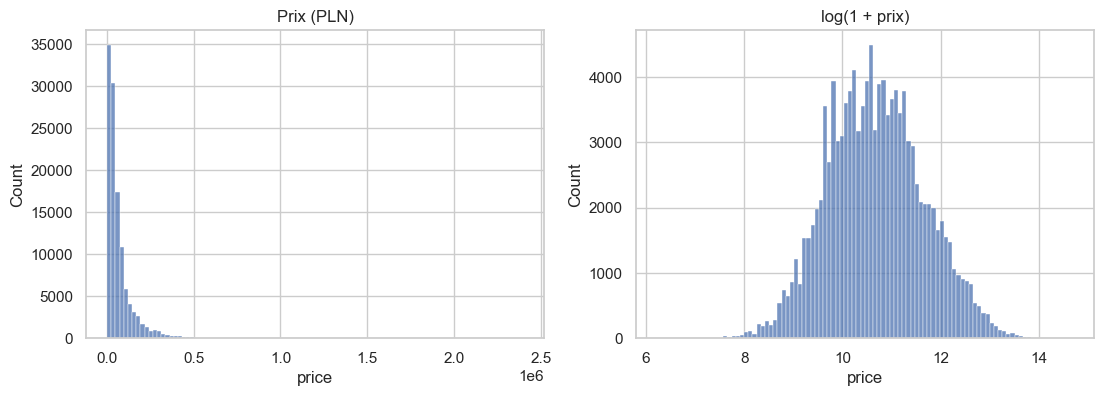

Asymétrie prix : 3.67  | asymétrie log(prix) : 0.12


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["price"], bins=100, ax=ax[0]).set_title("Prix (PLN)")
sns.histplot(np.log1p(df["price"]), bins=100, ax=ax[1]).set_title("log(1 + prix)")
plt.show()
print("Asymétrie prix :", round(df["price"].skew(), 2), " | asymétrie log(prix) :", round(np.log1p(df["price"]).skew(), 2))

Le prix est très asymétrique (quelques voitures très chères). En passant au logarithme on obtient une distribution presque normale : on entraînera les modèles sur `log(prix)`.

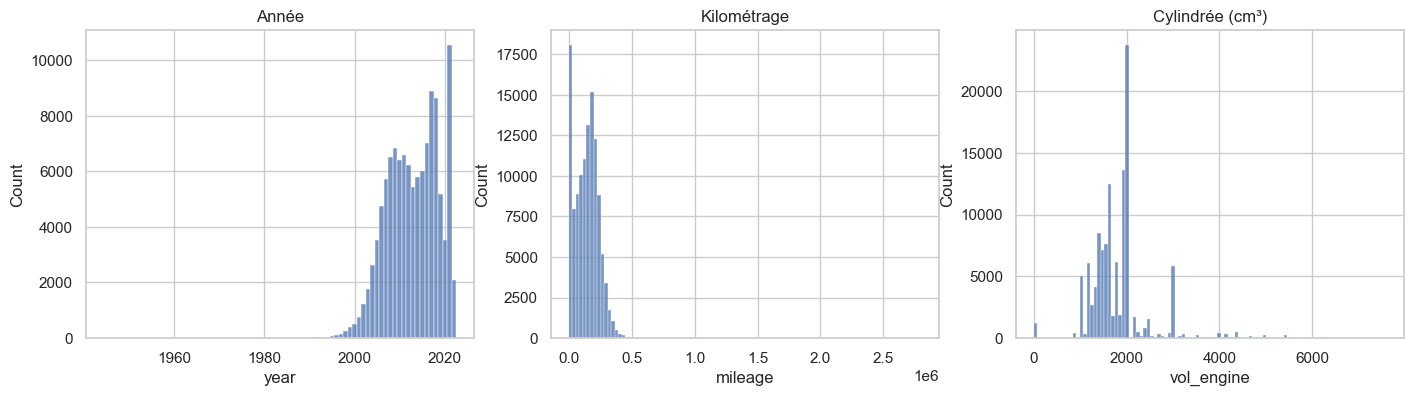

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(df["year"], discrete=True, ax=ax[0]).set_title("Année")
sns.histplot(df["mileage"], bins=100, ax=ax[1]).set_title("Kilométrage")
sns.histplot(df["vol_engine"], bins=100, ax=ax[2]).set_title("Cylindrée (cm³)")
plt.show()

### Variables catégorielles

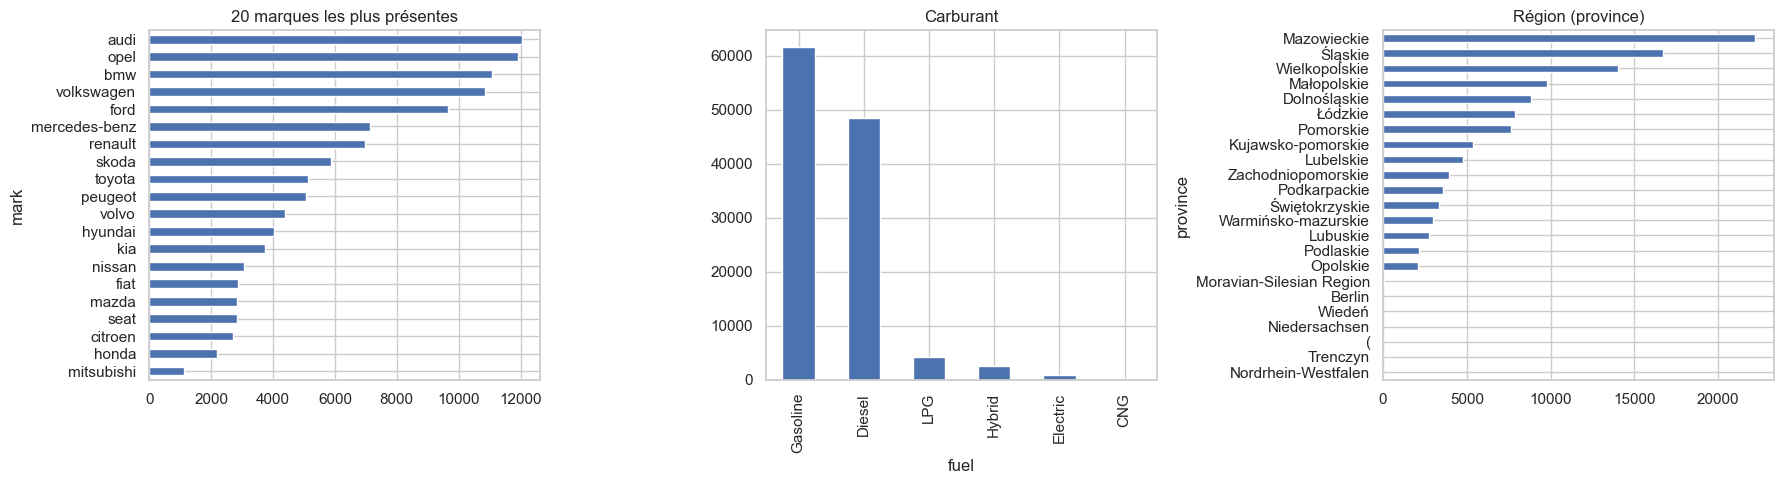

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
df["mark"].value_counts().head(20).plot.barh(ax=ax[0], title="20 marques les plus présentes").invert_yaxis()
df["fuel"].value_counts().plot.bar(ax=ax[1], title="Carburant")
df["province"].value_counts().plot.barh(ax=ax[2], title="Région (province)").invert_yaxis()
plt.tight_layout(); plt.show()

### Lien entre les variables et le prix

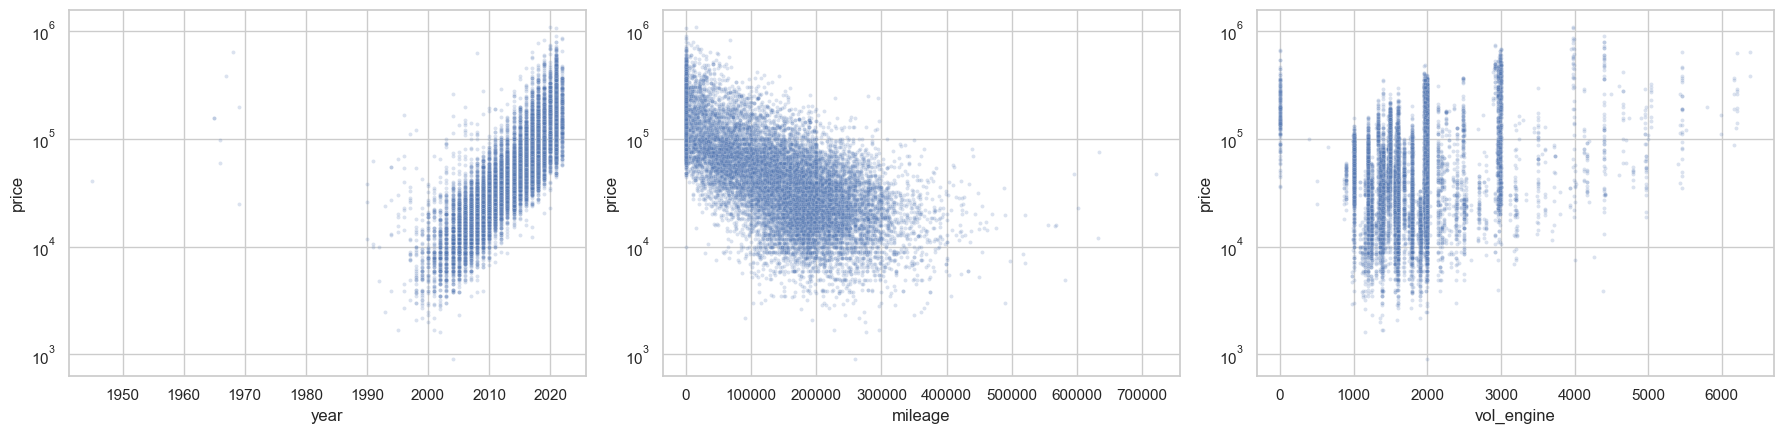

In [9]:
sample = df.sample(min(len(df), 15000), random_state=SEED)   # un échantillon suffit pour un nuage de points lisible
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sns.scatterplot(data=sample, x="year", y="price", alpha=.2, s=8, ax=ax[0]).set_yscale("log")
sns.scatterplot(data=sample, x="mileage", y="price", alpha=.2, s=8, ax=ax[1]).set_yscale("log")
sns.scatterplot(data=sample, x="vol_engine", y="price", alpha=.2, s=8, ax=ax[2]).set_yscale("log")
plt.tight_layout(); plt.show()

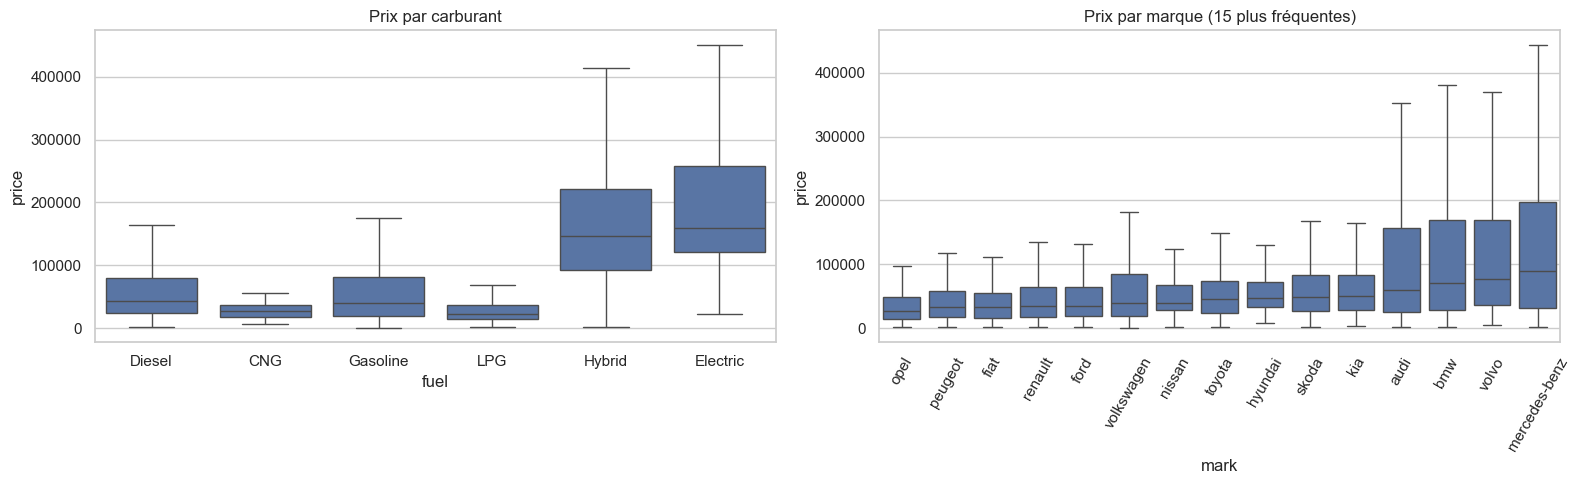

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df, x="fuel", y="price", ax=ax[0], showfliers=False).set_title("Prix par carburant")
top = df["mark"].value_counts().head(15).index
ordre = df[df["mark"].isin(top)].groupby("mark")["price"].median().sort_values().index
sns.boxplot(data=df[df["mark"].isin(top)], x="mark", y="price", order=ordre, ax=ax[1], showfliers=False).set_title("Prix par marque (15 plus fréquentes)")
ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

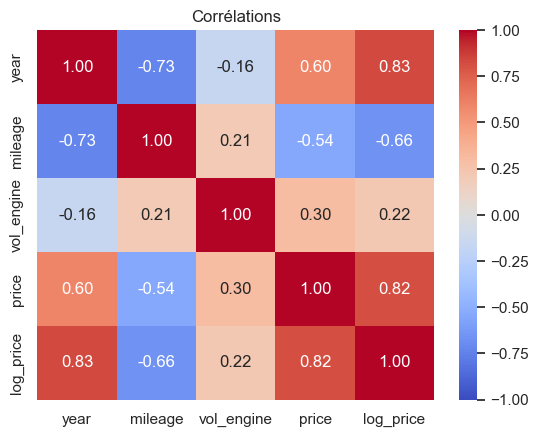

In [11]:
num = df[["year", "mileage", "vol_engine", "price"]].assign(log_price=np.log1p(df["price"]))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Corrélations"); plt.show()

**Bilan de l'EDA**
- Plus la voiture est récente, plus elle est chère ; plus elle a roulé, moins elle vaut : `year` et `mileage` sont les variables numériques les plus liées au prix.
- La marque et le carburant changent beaucoup le prix médian.
- Le prix est très asymétrique → passage au log.
- Il y a des doublons et des valeurs extrêmes à traiter.

## [Prétraitement]

## 3. Prétraitement (nettoyage)

1. Supprimer les doublons exacts (même annonce publiée plusieurs fois).
2. Remplacer les `generation_name` manquants par `"inconnu"` (le modèle n'a pas de génération indiquée, ce n'est pas une erreur).
3. Retirer les valeurs aberrantes : prix et kilométrage hors des quantiles 0,5 % – 99,5 %, cylindrée nulle pour un moteur thermique.

In [12]:
avant = len(df)
df = df.drop_duplicates()
df["generation_name"] = df["generation_name"].fillna("inconnu")
df = df.dropna()   # s'il reste des lignes incomplètes, elles sont très peu nombreuses

p_lo, p_hi = df["price"].quantile([.005, .995])
m_hi = df["mileage"].quantile(.995)
thermique = ~df["fuel"].str.lower().str.contains("electric")
df = df[df["price"].between(p_lo, p_hi) & (df["mileage"] <= m_hi) & ~(thermique & (df["vol_engine"] <= 0))]

print(f"Prix gardés entre {p_lo:,.0f} et {p_hi:,.0f} PLN, kilométrage <= {m_hi:,.0f} km")
print(f"{avant} -> {len(df)} lignes ({avant - len(df)} supprimées)")

Prix gardés entre 3,990 et 499,900 PLN, kilométrage <= 396,192 km
117927 -> 109509 lignes (8418 supprimées)


## [Transformation]

## 4. Transformation (feature engineering et encodage)

- `age` = 2022 − `year` (les données datent de janvier 2022) et `km_par_an` = kilométrage / âge : une voiture qui roule beaucoup chaque année s'use plus vite.
- `city` est retirée : plus de 4 000 villes, et `province` donne déjà la localisation.
- Encodage :
  - **one-hot** pour les catégories peu nombreuses (`fuel`, `province`) ;
  - **target encoding** pour `mark`, `model`, `generation_name` : chaque catégorie est remplacée par la moyenne de la cible pour cette catégorie (calculée avec validation croisée interne pour éviter la fuite de données) ;
  - **standardisation** des variables numériques (utile pour la régression linéaire).
- La cible est `log(1 + prix)` ; `TransformedTargetRegressor` repasse automatiquement en PLN au moment de prédire.

Le tout est mis dans un `Pipeline` : les encodeurs apprennent **uniquement sur le jeu d'entraînement**.

In [13]:
df["age"] = 2022 - df["year"]
df["km_par_an"] = df["mileage"] / df["age"].clip(lower=1)

cat_low = ["fuel", "province"]
cat_high = ["mark", "model", "generation_name"]
num_cols = ["year", "age", "mileage", "km_par_an", "vol_engine"]

X = df[cat_low + cat_high + num_cols]
y = df["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("Train :", X_train.shape, " Test :", X_test.shape)

preproc = ColumnTransformer([
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_low),
    ("target", TargetEncoder(random_state=SEED), cat_high),
    ("scale", StandardScaler(), num_cols),
])

# Aperçu du résultat de la transformation
Xt = preproc.fit_transform(X_train, np.log1p(y_train))
pd.DataFrame(Xt, columns=preproc.get_feature_names_out()).head()

Train : (87607, 10)  Test : (21902, 10)


,onehot__fuel_CNG,onehot__fuel_Diesel,onehot__fuel_Electric,onehot__fuel_Gasoline,onehot__fuel_Hybrid,onehot__fuel_LPG,onehot__province_Berlin,onehot__province_Dolnośląskie,onehot__province_Kujawsko-pomorskie,onehot__province_Lubelskie,onehot__province_Lubuskie,onehot__province_Mazowieckie,onehot__province_Małopolskie,onehot__province_Moravian-Silesian Region,onehot__province_Niedersachsen,onehot__province_Nordrhein-Westfalen,onehot__province_Opolskie,onehot__province_Podkarpackie,onehot__province_Podlaskie,onehot__province_Pomorskie,onehot__province_Warmińsko-mazurskie,onehot__province_Wielkopolskie,onehot__province_Zachodniopomorskie,onehot__province_Łódzkie,onehot__province_Śląskie,onehot__province_Świętokrzyskie,target__mark,target__model,target__generation_name,scale__year,scale__age,scale__mileage,scale__km_par_an,scale__vol_engine
0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.633771,10.617361,10.917102,0.555285,-0.555285,0.035158,0.930892,-0.770533
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,10.606964,10.337201,11.760735,0.916496,-0.916496,-0.176425,1.726701,-0.338068
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,10.736983,10.728636,11.068513,0.916496,-0.916496,0.011264,2.173160,-0.338068
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.195767,11.573392,10.888914,0.374679,-0.374679,-0.237911,0.188547,2.880499
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,11.017327,10.027309,10.318210,-0.889560,0.889560,1.468769,0.420529,1.145817


## [ML]

## 5. Modélisation (ML)

Trois modèles du plus simple au plus puissant :
- **Ridge** : régression linéaire régularisée, sert de référence ;
- **Random Forest** : moyenne de nombreux arbres de décision ;
- **HistGradientBoosting** : arbres construits les uns après les autres pour corriger les erreurs des précédents (rapide sur ~100 000 lignes).

In [14]:
def make_model(reg):
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", preproc), ("reg", reg)]),
        func=np.log1p, inverse_func=np.expm1)

modeles = {
    "Ridge": Ridge(alpha=1.0),
    "RandomForest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=500, learning_rate=0.08, random_state=SEED),
}

resultats, preds = [], {}
for nom, reg in modeles.items():
    m = make_model(reg).fit(X_train, y_train)
    p = m.predict(X_test)
    modeles[nom], preds[nom] = m, p
    resultats.append({
        "modèle": nom,
        "MAE (PLN)": mean_absolute_error(y_test, p),
        "RMSE (PLN)": mean_squared_error(y_test, p) ** 0.5,
        "MAPE (%)": 100 * mean_absolute_percentage_error(y_test, p),
        "R²": r2_score(y_test, p),
    })
resultats = pd.DataFrame(resultats).set_index("modèle").sort_values("MAE (PLN)")
resultats.style.format("{:,.3f}")

,MAE (PLN),RMSE (PLN),MAPE (%),R²
modèle,,,,
RandomForest,"7,806.310","16,010.269",13.344,0.950
HistGradientBoosting,"8,278.677","16,632.122",13.720,0.946
Ridge,"12,844.946","26,694.568",20.194,0.860


## [Éval]

## 6. Évaluation

- **MAE** : erreur moyenne en złotys, la plus facile à interpréter.
- **RMSE** : pénalise davantage les grosses erreurs.
- **MAPE** : erreur moyenne en pourcentage du prix.
- **R²** : part de la variance du prix expliquée (1 = parfait).

### Validation croisée du meilleur modèle
Un seul découpage train/test peut avoir de la chance ; la validation croisée à 5 plis donne une estimation plus fiable.

In [15]:
best = resultats.index[0]
cv = cross_val_score(make_model(modeles[best].regressor.named_steps["reg"]), X, y,
                     cv=KFold(5, shuffle=True, random_state=SEED), scoring="r2", n_jobs=-1)
print(f"{best} - R² en validation croisée : {cv.mean():.3f} ± {cv.std():.3f}")

RandomForest - R² en validation croisée : 0.948 ± 0.002


### Prédictions contre valeurs réelles et résidus

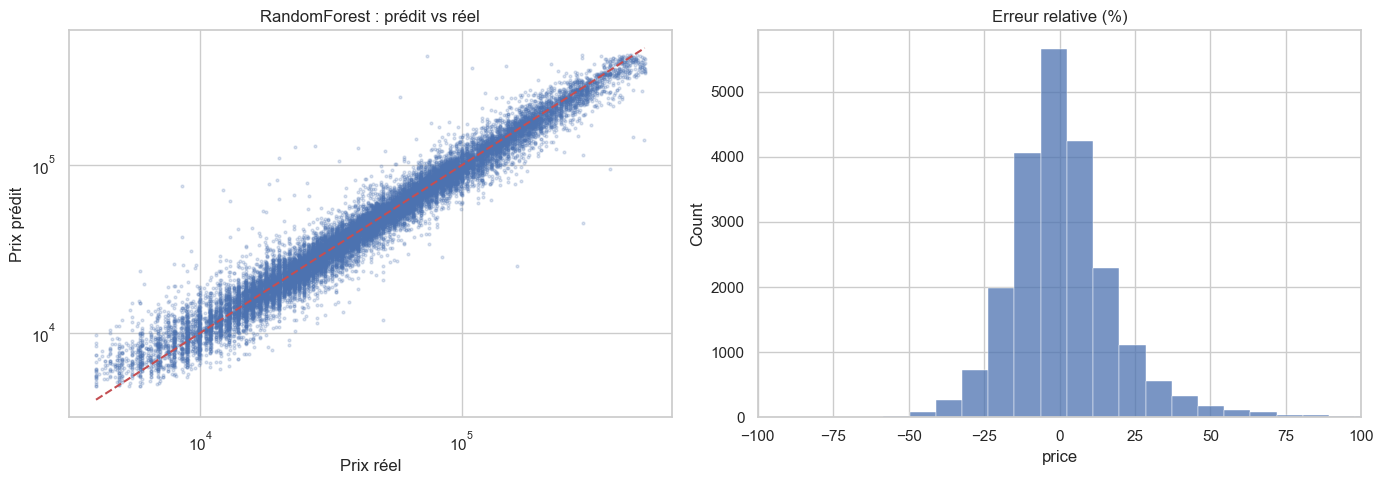

In [16]:
p = preds[best]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(y_test, p, s=4, alpha=.2)
lim = [y_test.min(), y_test.max()]
ax[0].plot(lim, lim, "r--"); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set(xlabel="Prix réel", ylabel="Prix prédit", title=f"{best} : prédit vs réel")
sns.histplot((p - y_test) / y_test * 100, bins=100, ax=ax[1]).set(xlim=(-100, 100), title="Erreur relative (%)")
plt.tight_layout(); plt.show()

### Erreur par tranche de prix

In [17]:
tranches = pd.qcut(y_test, 5)
pd.DataFrame({"prix": y_test, "erreur_abs": abs(p - y_test), "erreur_%": abs(p - y_test) / y_test * 100}) \
  .groupby(tranches, observed=True)[["erreur_abs", "erreur_%"]].median().round(1)

,erreur_abs,erreur_%
price,,
"(3989.999, 18700.0]",1583.8,13.2
"(18700.0, 31900.0]",2345.2,9.6
"(31900.0, 52900.0]",3425.6,8.2
"(52900.0, 93900.0]",5580.3,8.0
"(93900.0, 499900.0]",14248.5,8.9


### Importance des variables
Importance par permutation : on mélange une colonne et on regarde de combien le score baisse. Plus il baisse, plus la variable compte.

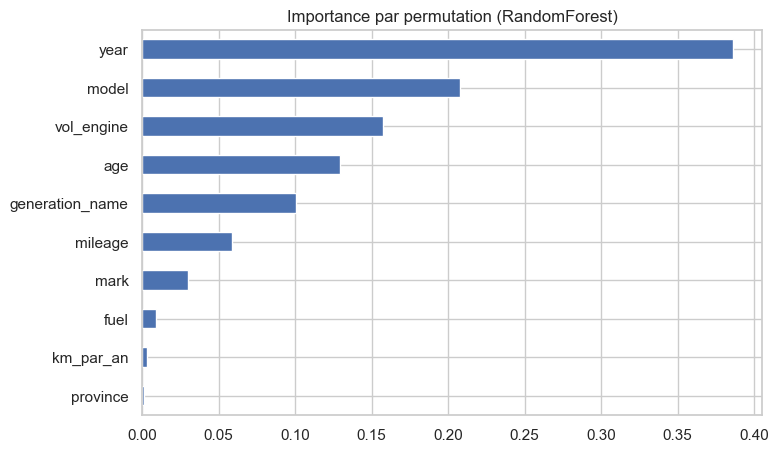

In [18]:
xs = X_test.sample(min(len(X_test), 5000), random_state=SEED)   # un échantillon suffit et va plus vite
imp = permutation_importance(modeles[best], xs, y_test.loc[xs.index], n_repeats=5, random_state=SEED, scoring="r2", n_jobs=-1)
pd.Series(imp.importances_mean, index=X_test.columns).sort_values().plot.barh(figsize=(8, 5), title=f"Importance par permutation ({best})")
plt.show()

## [Data]

## 7. Version PySpark

La consigne du TP3 demande de traiter aussi les données avec **PySpark**. On refait toute la chaîne avec Spark :
- les données sont un **DataFrame Spark**, découpé en partitions et traité en parallèle sur tous les cœurs ;
- les calculs sont **paresseux** : Spark n'exécute rien avant une action (`count`, `show`, `fit`...), puis optimise tout le plan d'un coup ;
- le ML utilise **Spark MLlib** (`Pipeline`, `StringIndexer`, `OneHotEncoder`, `VectorAssembler`, régresseurs distribués).

Avec ~110 000 lignes, pandas est plus rapide (pas de JVM, pas de coût de distribution). Mais le même code Spark passerait à des millions d'annonces ou à un cluster sans changement, seulement en modifiant `master`.

### 7.1 Lancement de Spark et chargement
On relit le même CSV (variable `CSV` de la section 1) avec `spark.read.csv`. `inferSchema` détecte les types des colonnes.

In [19]:
import os, sys
from pathlib import Path
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
jdks = sorted(Path.home().glob(".jdks/*"))
if jdks:   # shortcut: prend le dernier JDK de ~/.jdks ; sinon définir JAVA_HOME à la main
    os.environ["JAVA_HOME"] = str(jdks[-1])

from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline as SparkPipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler as SparkScaler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor as SparkRF, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

spark = (SparkSession.builder.master("local[*]").appName("TP3 Car Prices")
         .config("spark.driver.host", "127.0.0.1").config("spark.driver.bindAddress", "127.0.0.1")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")   # ~100 000 lignes : 8 partitions suffisent (200 par défaut)
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| cœurs :", spark.sparkContext.defaultParallelism)

Spark 4.2.0 | cœurs : 12


In [20]:
sdf = spark.read.csv(str(CSV), header=True, inferSchema=True)
sdf = sdf.drop(*[c for c in sdf.columns if c.startswith("_c") or c.startswith("Unnamed")])
sdf.printSchema()
print("Lignes :", sdf.count(), "| partitions :", sdf.rdd.getNumPartitions())

root
 |-- mark: string (nullable = true)
 |-- model: string (nullable = true)
 |-- generation_name: string (nullable = true)
 |-- year: integer (nullable = true)
 |-- mileage: integer (nullable = true)
 |-- vol_engine: integer (nullable = true)
 |-- fuel: string (nullable = true)
 |-- city: string (nullable = true)
 |-- province: string (nullable = true)
 |-- price: integer (nullable = true)



Lignes : 117927 | partitions : 3


## [EDA]

### 7.2 EDA avec Spark
Valeurs manquantes, nombre de valeurs distinctes, doublons et statistiques sont calculés par des agrégations distribuées. Seul le petit résultat revient au driver. On doit retrouver les chiffres de la section 2 : 30 085 `generation_name` manquants et 6 473 doublons.

In [21]:
# Valeurs manquantes et nombre de valeurs différentes, calculés en une seule passe
sdf.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in sdf.columns]).show()
sdf.select([F.countDistinct(c).alias(c) for c in sdf.columns]).show()
print("Doublons :", sdf.count() - sdf.dropDuplicates().count())
sdf.select("price", "year", "mileage", "vol_engine").summary("mean", "min", "25%", "50%", "75%", "max").show()

+----+-----+---------------+----+-------+----------+----+----+--------+-----+
|mark|model|generation_name|year|mileage|vol_engine|fuel|city|province|price|
+----+-----+---------------+----+-------+----------+----+----+--------+-----+
|   0|    0|          30085|   0|      0|         0|   0|   0|       0|    0|
+----+-----+---------------+----+-------+----------+----+----+--------+-----+



+----+-----+---------------+----+-------+----------+----+----+--------+-----+
|mark|model|generation_name|year|mileage|vol_engine|fuel|city|province|price|
+----+-----+---------------+----+-------+----------+----+----+--------+-----+
|  23|  328|            364|  54|  35394|       508|   6|4427|      23| 9310|
+----+-----+---------------+----+-------+----------+----+----+--------+-----+



Doublons : 6473


+-------+-----------------+------------------+------------------+------------------+
|summary|            price|              year|           mileage|        vol_engine|
+-------+-----------------+------------------+------------------+------------------+
|   mean|70299.88479313474|2012.9252588465745|140976.78614736235|1812.0577815088996|
|    min|              500|              1945|                 0|                 0|
|    25%|            21000|              2009|             67000|              1461|
|    50%|            41900|              2013|            146250|              1796|
|    75%|            83555|              2018|            203000|              1995|
|    max|          2399900|              2022|           2800000|              7600|
+-------+-----------------+------------------+------------------+------------------+



`percentile_approx` calcule une médiane approchée en une seule passe, ce qui est indispensable sur de gros volumes : une médiane exacte demanderait de trier toutes les données.

In [22]:
# Prix médian par carburant et par marque (agrégations distribuées)
sdf.groupBy("fuel").agg(F.count("*").alias("n"), F.percentile_approx("price", 0.5).alias("prix_median")) \
   .orderBy(F.desc("n")).show()
sdf.groupBy("mark").agg(F.count("*").alias("n"), F.percentile_approx("price", 0.5).alias("prix_median")) \
   .orderBy(F.desc("n")).show(10)

+--------+-----+-----------+
|    fuel|    n|prix_median|
+--------+-----+-----------+
|Gasoline|61597|      39900|
|  Diesel|48476|      43800|
|     LPG| 4301|      21900|
|  Hybrid| 2621|     145800|
|Electric|  885|     159900|
|     CNG|   47|      26900|
+--------+-----+-----------+



+-------------+-----+-----------+
|         mark|    n|prix_median|
+-------------+-----+-----------+
|         audi|12031|      59000|
|         opel|11914|      26999|
|          bmw|11070|      70000|
|   volkswagen|10848|      39500|
|         ford| 9664|      34500|
|mercedes-benz| 7136|      89800|
|      renault| 6976|      33800|
|        skoda| 5888|      48600|
|       toyota| 5120|      45500|
|      peugeot| 5056|      32900|
+-------------+-----+-----------+
only showing top 10 rows


On retrouve les conclusions de l'EDA pandas : les hybrides et les électriques sont les plus chers, le GPL est le moins cher, et Mercedes, BMW et Audi sont au-dessus d'Opel et de Renault.

## [Prétraitement]

### 7.3 Prétraitement avec Spark
Mêmes règles qu'en section 3. Les quantiles viennent de `approxQuantile` (erreur relative de 0,1 %), donc les bornes peuvent différer de quelques złotys de la version pandas, et le nombre de lignes gardées aussi (environ 109 200 contre 109 509).
`cache()` garde le résultat en mémoire, parce qu'il sera réutilisé plusieurs fois.

In [23]:
# Mêmes règles que la version pandas : doublons, generation_name manquant, valeurs aberrantes
s = sdf.dropDuplicates().fillna({"generation_name": "inconnu"}).dropna()
(p_lo, p_hi), (m_hi,) = s.approxQuantile("price", [.005, .995], 0.001), s.approxQuantile("mileage", [.995], 0.001)
thermique = ~F.lower("fuel").contains("electric")
s = s.filter(F.col("price").between(p_lo, p_hi) & (F.col("mileage") <= m_hi) & ~(thermique & (F.col("vol_engine") <= 0))).cache()
print(f"Prix gardés entre {p_lo:,.0f} et {p_hi:,.0f} PLN, kilométrage <= {m_hi:,.0f} km -> {s.count()} lignes")

Prix gardés entre 4,000 et 473,000 PLN, kilométrage <= 386,300 km -> 109222 lignes


## [Transformation]

### 7.4 Transformation avec Spark
- Mêmes variables qu'en section 4 : `age`, `km_par_an`, cible `log_price`.
- **Target encoding fait à la main** avec un `groupBy` et une jointure : pour chaque marque, modèle et génération, on calcule la moyenne de `log_price` **sur le train uniquement**, lissée vers la moyenne globale (`K = 20`) pour les valeurs rares. La table d'encodage est petite, donc on l'envoie à tous les workers (`broadcast`) et la jointure se fait sans shuffle.
- `StringIndexer` + `OneHotEncoder` pour `fuel` et `province`, `VectorAssembler` pour regrouper toutes les variables dans un seul vecteur, puis `StandardScaler`.
- `localCheckpoint()` matérialise les jeux train et test et coupe la lignée des jointures. Sans ça, chaque itération des arbres recalculait toutes les jointures et la JVM finissait par planter.

In [24]:
s = (s.withColumn("age", 2022 - F.col("year"))
      .withColumn("km_par_an", F.col("mileage") / F.greatest(F.col("age"), F.lit(1)))
      .withColumn("log_price", F.log1p("price")))
train_s, test_s = s.randomSplit([0.8, 0.2], seed=SEED)

# Target encoding des colonnes à forte cardinalité : moyenne de log_price par valeur, calculée sur le train
# seulement (groupBy + join), lissée vers la moyenne globale pour les valeurs rares.
moy, K = train_s.agg(F.avg("log_price")).first()[0], 20
for c in ["mark", "model", "generation_name"]:
    enc = train_s.groupBy(c).agg(((F.sum("log_price") + K * moy) / (F.count("*") + K)).alias(c + "_te"))
    train_s = train_s.join(F.broadcast(enc), c, "left")
    test_s = test_s.join(F.broadcast(enc), c, "left").fillna({c + "_te": moy})   # valeur jamais vue -> moyenne

feats = ["mark_te", "model_te", "generation_name_te", "year", "age", "mileage", "km_par_an", "vol_engine"]
prep_spark = [
    StringIndexer(inputCols=["fuel", "province"], outputCols=["fuel_i", "province_i"], handleInvalid="keep"),
    OneHotEncoder(inputCols=["fuel_i", "province_i"], outputCols=["fuel_oh", "province_oh"]),
    VectorAssembler(inputCols=feats + ["fuel_oh", "province_oh"], outputCol="raw"),
    SparkScaler(inputCol="raw", outputCol="features"),
]
train_s, test_s = train_s.localCheckpoint(), test_s.localCheckpoint()   # matérialise et coupe la lignée (jointures) avant le ML
print("Train :", train_s.count(), " Test :", test_s.count())

Train : 87625  Test : 21597


## [ML]

### 7.5 Modélisation avec Spark MLlib
Trois modèles, comme avec scikit-learn : `LinearRegression` (référence), `RandomForestRegressor` et `GBTRegressor` (gradient boosting). Chaque modèle est un `Pipeline` Spark (encodage + modèle) entraîné sur `log_price`. Les prédictions sont repassées en złotys avec `expm1` avant le calcul des métriques.

In [25]:
modeles_spark = {
    "LinearRegression": LinearRegression(labelCol="log_price", regParam=0.01),
    "RandomForest": SparkRF(labelCol="log_price", numTrees=60, maxDepth=12, seed=SEED),
    "GBT": GBTRegressor(labelCol="log_price", maxIter=60, maxDepth=6, seed=SEED),
}
ev = {m: RegressionEvaluator(labelCol="price", predictionCol="pred_price", metricName=m) for m in ["mae", "rmse", "r2"]}
res_spark = []
import time
for nom, reg in modeles_spark.items():
    t0 = time.time()
    m = SparkPipeline(stages=prep_spark + [reg]).fit(train_s)
    pr = m.transform(test_s).withColumn("pred_price", F.expm1("prediction"))   # retour en złotys
    mape = pr.select(F.avg(F.abs(F.col("pred_price") - F.col("price")) / F.col("price"))).first()[0]
    res_spark.append((nom, ev["mae"].evaluate(pr), ev["rmse"].evaluate(pr), 100 * mape, ev["r2"].evaluate(pr)))
    print(f"{nom:17s} MAE={res_spark[-1][1]:,.0f}  RMSE={res_spark[-1][2]:,.0f}  MAPE={res_spark[-1][3]:.1f}%  R²={res_spark[-1][4]:.3f}  ({time.time() - t0:.0f} s)")

LinearRegression  MAE=13,001  RMSE=26,482  MAPE=20.4%  R²=0.855  (6 s)


RandomForest      MAE=9,070  RMSE=18,403  MAPE=14.9%  R²=0.930  (29 s)


GBT               MAE=9,890  RMSE=19,560  MAPE=15.9%  R²=0.921  (104 s)


## [Éval]

### 7.6 Évaluation et comparaison avec scikit-learn
Mêmes métriques qu'en section 6 (MAE, RMSE, MAPE, R²), calculées avec `RegressionEvaluator` sur le jeu de test Spark.

In [26]:
res_spark_df = spark.createDataFrame(res_spark, ["modèle", "MAE (PLN)", "RMSE (PLN)", "MAPE (%)", "R²"]).orderBy(F.desc("R²"))
res_spark_df.show()


# Comparaison avec les résultats scikit-learn de la section 5 (petits tableaux : toPandas() sans risque)
comparaison = pd.concat({"scikit-learn": resultats, "PySpark": res_spark_df.toPandas().set_index("modèle")})
comparaison.style.format("{:,.3f}")

+----------------+-----------------+------------------+------------------+------------------+
|          modèle|        MAE (PLN)|        RMSE (PLN)|          MAPE (%)|                R²|
+----------------+-----------------+------------------+------------------+------------------+
|    RandomForest|9069.829397979054|18403.122666096137|14.878925672156734|0.9302046814382469|
|             GBT|9889.734705498839|19559.659940278434|15.908921727533537|0.9211565078438044|
|LinearRegression|13001.26605982644|26481.860919426334|20.357329020493868|0.8554759069491861|
+----------------+-----------------+------------------+------------------+------------------+



**Bilan de la version PySpark** (résultats de notre test : R² de 0,855 en linéaire, 0,930 en Random Forest et 0,921 en GBT, à comparer avec 0,860 / 0,950 / 0,946 pour scikit-learn) :
- Spark retrouve le même classement : les arbres battent nettement le modèle linéaire.
- Les arbres Spark sont un peu moins bons, parce que la Random Forest de MLlib est limitée en profondeur (`maxDepth` ≤ 30, ici 12) et découpe les variables numériques en 32 intervalles (`maxBins`), alors que scikit-learn fait des arbres sans limite de profondeur sur les valeurs exactes. Le découpage train/test n'est pas non plus exactement le même (`randomSplit`).
- Sur 10 Mo de données, Spark est plus lent que pandas (démarrage de la JVM, planification des tâches). Son intérêt apparaît quand les données ne tiennent plus sur une machine : le code ne change pas.

On arrête la session Spark pour libérer la mémoire.

In [27]:
spark.stop()

## [Conclusion]

## 8. Conclusion

- L'EDA montre que l'année, le kilométrage, la marque/le modèle et le carburant expliquent l'essentiel du prix.
- Le prétraitement retire doublons et valeurs aberrantes ; le passage au log de la cible stabilise l'apprentissage.
- Le target encoding permet d'utiliser `model` et `generation_name` (des centaines de valeurs) sans exploser le nombre de colonnes.
- Les modèles à base d'arbres battent nettement la régression linéaire car les effets ne sont pas linéaires (une voiture perd beaucoup de valeur les premières années puis moins).
- **PySpark** reproduit toute la chaîne de façon distribuée (DataFrame, agrégations, target encoding par `groupBy`/`broadcast`, MLlib) avec le même classement des modèles. Il est un peu moins précis et plus lent à cette échelle, mais il passe à l'échelle sans réécriture.
- Pistes d'amélioration (citées par l'auteur du dataset) : ajouter la carrosserie, la puissance, la couleur, l'équipement.